# 07 · Final Evaluation (once-only test)

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Present the single, locked evaluation of the frozen model on the 917-image held-out test split. **This notebook reads saved results only; it never calls the evaluator and never reads test images.**

**Research questions**

1. How does the frozen model perform on unseen test scenes?
2. Do test results agree with validation?
3. Where does the detector fail, especially on large rocks?

**Inputs (published, pixel-free artifacts)**

- `artifacts/evaluation/test_results.json`
- `artifacts/provenance/TEST_RUN_LOCK.json`
- `artifacts/figures/f_test_*.png`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. Protocol and lock
The test split was evaluated **once**, after the model, threshold, NMS and evaluation policy had been frozen and their SHA-256 hashes
verified. A lock file prevents any second run, and test results were never used for tuning.

In [2]:
import json
lock = A.load_json("provenance/TEST_RUN_LOCK.json"); r = A.test_results()
pd.Series({"started": lock["started"], "finished": lock["finished"], "frozen config sha256": lock["frozen_config_sha256"][:16] + "...",
           "model sha256": lock["model_sha256"][:16] + "...", "test images": 917, "protocol": r["protocol"],
           "max_det truncation affecting conf 0.20": r["max_det_check"]["images_where_cap_affects_conf_0.20"],
           "protected data unchanged after run": all(r["protected_trees_unchanged"].values())}).to_frame("once-only test evaluation")

,once-only test evaluation
started,2026-10-09T23:14:06
finished,2026-10-09T23:15:17
frozen config sha256,efdc5802cbc3a4f0...
model sha256,413d0481a728a310...
test images,917
protocol,predict conf 0.001 / NMS IoU 0.6 / max_det 300 / imgsz 736 (as validation); operating ...
max_det truncation affecting conf 0.20,0
protected data unchanged after run,True


## 2. Headline results (confidence 0.20)

In [3]:
A.test_policy_table()

,policy,precision,recall,F1,FP/image,AP50,AP50-95,TP,FP,FN
0,PRIMARY_review_ignores,0.698,0.774,0.734,9.481,0.777,0.428,20108.0,8694.0,5879.0
1,SECONDARY_review_plus_subthreshold_PROPOSED,0.779,0.774,0.776,6.213,0.803,0.440,20108.0,5697.0,5879.0
2,REFERENCE_no_ignores,0.534,0.774,0.632,19.170,0.664,0.370,20108.0,17579.0,5879.0
3,"VALIDATION (primary, same frozen config)",0.696,0.775,0.734,9.470,0.776,0.431,NaN,NaN,NaN


The **primary** row is the official result. Recall is identical under every policy, because ignore regions change how
predictions are counted, never the ground truth. Test agrees with validation to within ±0.004 on every headline metric, so the selection
did not overfit the validation split.

That agreement is **not** evidence of generalisation to real lunar imagery. Both splits come from the same synthetic distribution and
the same automated labelling.

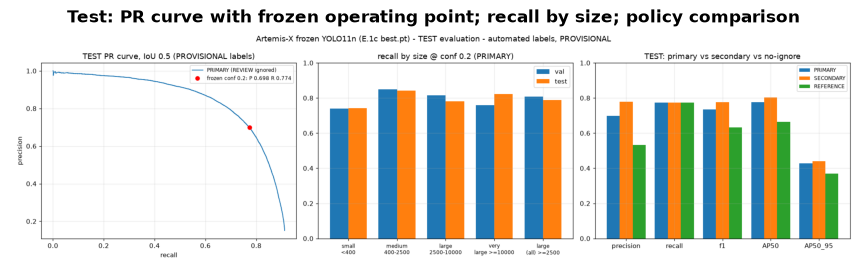

In [4]:
P.show_png(FIG / "f_test_evaluation.png", "Test: PR curve with frozen operating point; recall by size; policy comparison")

## 3. Recall by rock size, with 95% Wilson intervals

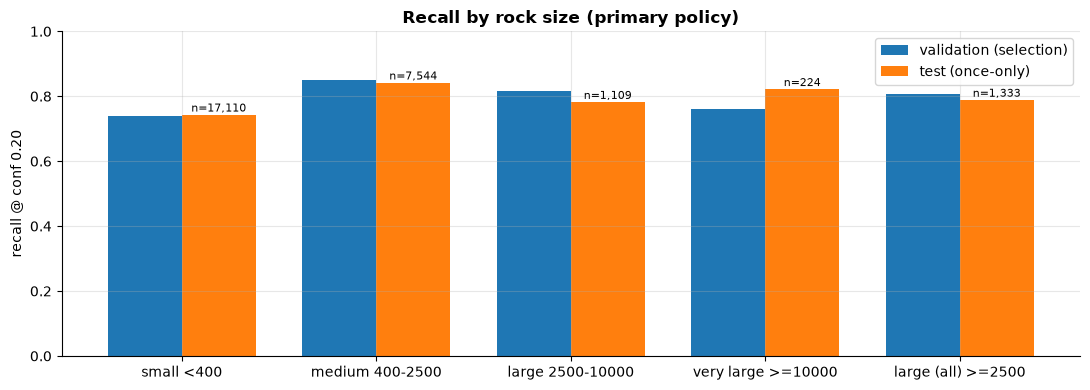

,size bin (px^2),GT (test),recall test,recall val,precision test,AP50 test,95% CI
0,small <400,17110,0.743,0.740,0.647,0.726,0.736-0.749
1,medium 400-2500,7544,0.842,0.849,0.813,0.870,0.833-0.850
2,large 2500-10000,1109,0.782,0.815,0.847,0.835,0.757-0.805
3,very large >=10000,224,0.821,0.760,0.760,0.817,0.766-0.866
4,large (all) >=2500,1333,0.788,0.807,0.828,0.828,0.766-0.810


In [5]:
from artemis_x.evaluation.metrics import wilson_interval
st = A.test_size_table()
ci = [wilson_interval(round(r * n), n) for r, n in zip(st["recall test"], st["GT (test)"])]
st["95% CI"] = [f"{lo:.3f}-{hi:.3f}" for lo, hi in ci]
P.size_recall(st)
st

About **one large rock in five is missed** (recall 0.788 for rocks of at least 2,500 px$^2$). The very-large bin is small
(n = 224), so its val/test difference (0.760 vs 0.821) is within sampling noise. The intervals assume independent boxes, so the true
uncertainty is larger.

## 4. Error analysis

In [6]:
pb = pd.DataFrame({k: v["prediction_breakdown"] for k, v in r["policies"].items()})
pb

,PRIMARY_review_ignores,SECONDARY_review_plus_subthreshold_PROPOSED,REFERENCE_no_ignores
tp,20108,20108,20108
ignored,8885,11882,0
fp_duplicate,465,457,467
fp_localisation,3747,3623,3966
fp_background,4482,1617,13146


In [7]:
fn = r["fn_analysis_primary"]
pd.DataFrame(fn["by_size"]).T.assign(total=lambda x: x.sum(axis=1))

,found_below_threshold,localisation_iou_0.1_0.5,near_miss_iou_lt_0.1,total
small <400,2639,891,870,4400
medium 400-2500,782,275,139,1196
large 2500-10000,144,57,42,243
very large >=10000,19,10,11,40


In [8]:
edge = A.load_json("evaluation/large_rock_edge_analysis.json")["results"]
pd.DataFrame({s: {k: f"{v['recall']:.3f} (n={v['gt']})" for k, v in d.items()} for s, d in edge.items()})

,val,test
side/top-edge,0.820 (n=183),0.801 (n=171)
interior,0.806 (n=1060),0.792 (n=989)
bottom-edge,0.801 (n=166),0.751 (n=173)


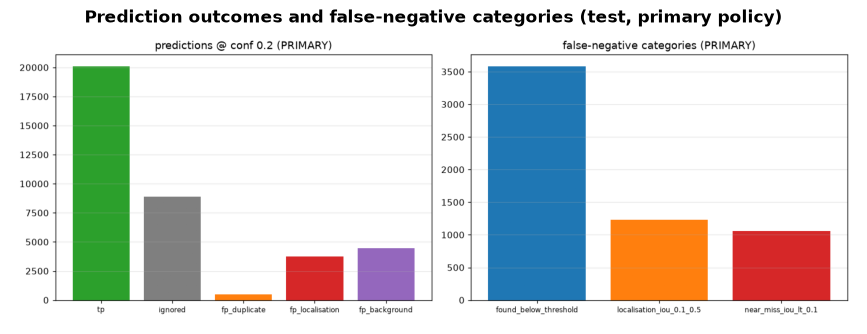

In [9]:
P.show_png(FIG / "f_test_confusion_analysis.png", "Prediction outcomes and false-negative categories (test, primary policy)")

**Qualitative failure cases** (local-only overlays, not committed):
- craters, cliff faces and touching-boulder clusters labelled as a single rock (label artefacts);
- isolated near-field boulders at the bottom of the frame;
- rocks in deep shadow.

The near-field (bottom-edge) effect seen visually is **not** confirmed statistically: 0.751 vs 0.792, within the uncertainty.

## 5. Limitations
1. **Labels:** automated and not human-validated. Visible artefacts inflate the large-rock miss counts, and other label errors could
   bias any metric in either direction.
2. **Policy dependence:** AP50 ranges from 0.664 to 0.803 across policies. Only the primary policy is approved.
3. **Domain:** synthetic renders only. No real lunar imagery and no Webots imagery have been evaluated.
4. **Statistics:** one training seed; size-bin intervals assume independent boxes.
5. **Safety:** missing about 21% of large rocks means this detector alone is **not sufficient** for obstacle avoidance. A rover needs
   redundant hazard sensing (stereo or depth), temporal tracking and conservative margins.

## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [10]:
A.provenance(['evaluation/test_results.json', 'provenance/TEST_RUN_LOCK.json', 'figures/f_test_evaluation.png'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/evaluation/test_results.json,COPY,experiments/task-f/test-evaluation-001/test_results.json,a3d6d6088fc8fa2e...
1,artifacts/provenance/TEST_RUN_LOCK.json,COPY,experiments/task-f/test-evaluation-001/TEST_RUN_LOCK.json,8bf83421e2d2dde5...
2,artifacts/figures/f_test_evaluation.png,COPY,experiments/task-f/test-evaluation-001/test_evaluation_figures.png,2f06ad17c621d189...


## Conclusion
- On the held-out test split, the frozen detector reaches precision 0.698, recall 0.774, F1 0.734, 9.48 false positives per
  image, AP50 0.777 and AP50-95 0.428. These figures use the primary policy and are **provisional**.
- Results reproduce validation closely. The dominant open questions are label quality and real-domain transfer, not overfitting
  during model selection.

**Next:** [08_inference_demo.ipynb](08_inference_demo.ipynb)